# Network visualization with Python

DSC 402/502 · Data Visualization · Prof. Steven Wilson

1. NetworkX basics: nodes, edges, attributes, drawing
2. An interactive network with Plotly
3. **Movie dialogs:** a character network built from real film scripts, which you'll adapt for this week's exercise

> Start the install cell in Part 3 first if you're short on time; downloading the corpus takes a minute or two.

## Part 1 · NetworkX basics

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

In [ ]:
G = nx.Graph()
G.add_node(1)
G

In [ ]:
G.nodes

NodeView((1,))

In [ ]:
G.add_nodes_from([2, 3])
G.add_edges_from([(1, 2), (2, 3)])
G.edges

EdgeView([(1, 2), (2, 3)])

Nodes and edges can carry attributes, stored like dictionaries:

In [ ]:
G.edges[1, 2]['color'] = "blue"
G.edges[1, 2]

{'color': 'blue'}

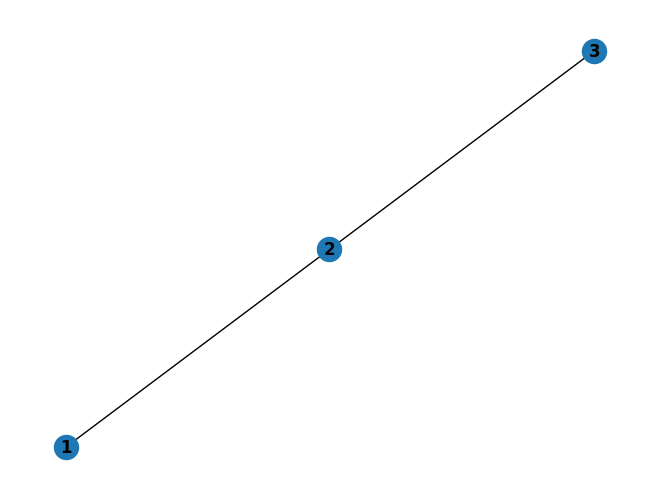

In [ ]:
nx.draw(G, with_labels=True, font_weight='bold')

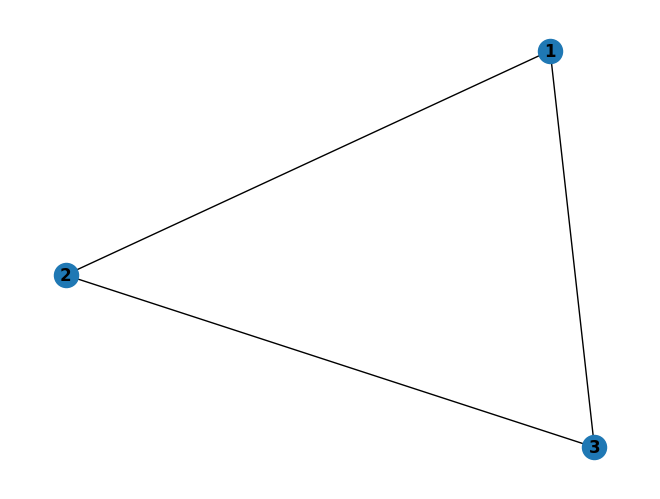

In [ ]:
G.add_edge(3, 1)
nx.draw(G, with_labels=True, font_weight='bold')

Save a drawing as an image, or export the graph as DOT (the Graphviz format from the slides):

strict graph {
1;
2;
3;
1 -- 2 [color=blue];
1 -- 3;
2 -- 3;
}



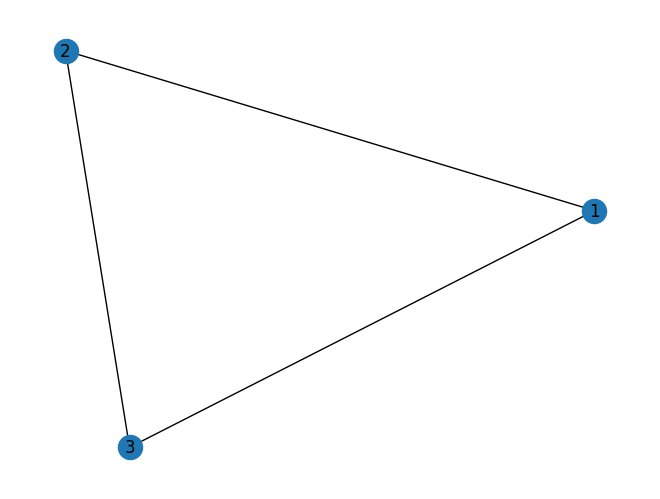

In [ ]:
nx.draw(G, with_labels=True)
plt.savefig("mygraph.png", dpi=200, bbox_inches="tight")

nx.nx_pydot.write_dot(G, "mygraph.dot")
print(open("mygraph.dot").read())

## Part 2 · An interactive network with Plotly

A random geometric graph: 100 points dropped in a unit square, connected when they're within 0.125 of each other. Each node already has a `pos` attribute, so we don't need a layout algorithm.

In [ ]:
import plotly.graph_objects as go

G2 = nx.random_geometric_graph(100, 0.125, seed=42)
G2.nodes[0]

{'pos': [0.6394267984578837, 0.025010755222666936]}

In [ ]:
# Edges: one line trace, with None breaking the line between edges
edge_x, edge_y = [], []
for u, v in G2.edges():
    x0, y0 = G2.nodes[u]['pos']
    x1, y1 = G2.nodes[v]['pos']
    edge_x += [x0, x1, None]
    edge_y += [y0, y1, None]

edge_trace = go.Scatter(x=edge_x, y=edge_y, mode='lines',
                        line=dict(width=0.5, color='#888'), hoverinfo='none')

# Nodes: colored by degree (number of connections)
node_x = [G2.nodes[n]['pos'][0] for n in G2.nodes()]
node_y = [G2.nodes[n]['pos'][1] for n in G2.nodes()]
degrees = [G2.degree(n) for n in G2.nodes()]

node_trace = go.Scatter(
    x=node_x, y=node_y, mode='markers',
    hoverinfo='text',
    text=[f'# of connections: {d}' for d in degrees],
    marker=dict(
        color=degrees,
        colorscale='YlGnBu', reversescale=True,
        size=10, line_width=2, showscale=True,
        colorbar=dict(thickness=15, title=dict(text='Node connections', side='right')),
    ))

fig = go.Figure(
    data=[edge_trace, node_trace],
    layout=go.Layout(
        title=dict(text='Network graph made with Python', font=dict(size=16)),
        showlegend=False, hovermode='closest',
        margin=dict(b=20, l=5, r=5, t=40),
        xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
        yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    ))
fig.show()

Adapted from the [Plotly network graph example](https://plotly.com/python/network-graphs/).

## Part 3 · Movie dialogs as a character network

We'll use the [Cornell Movie-Dialogs Corpus](https://convokit.cornell.edu/documentation/movie.html) through [ConvoKit](https://convokit.cornell.edu/). It holds about 300,000 lines from 617 movie scripts, grouped into conversations between characters.

The plan:
1. Pick a movie and pull out its conversations
2. For every pair of characters, count how many conversations they share
3. Make each character a node and each pair an edge, weighted by that count

In [ ]:
!pip install -q convokit
from convokit import Corpus, download

corpus = Corpus(filename=download("movie-corpus"))

ConvoKit organizes everything as **speakers**, **utterances** (single lines) and **conversations**. Each one carries a `meta` dictionary with extra information.

In [ ]:
corpus.print_summary_stats()

Number of Speakers: 9035
Number of Utterances: 304713
Number of Conversations: 83097


In [ ]:
utt = corpus.random_utterance()
print(utt.text)
print(utt.speaker.meta)

That it is.
ConvoKitMeta({'character_name': 'ROPER', 'movie_idx': 'm133', 'movie_name': 'metro', 'gender': 'm', 'credit_pos': '1'})


### Pick a movie

In [ ]:
movie_names = sorted({conv.meta['movie_name'] for conv in corpus.iter_conversations()})
print(len(movie_names), "movies")
print(movie_names[:25])

617 movies
['"murderland"', '10 things i hate about you', '1492: conquest of paradise', '15 minutes', '2001: a space odyssey', '48 hrs.', '8mm', 'a bucket of blood', 'a clockwork orange', "a hard day's night", 'a nightmare on elm street', 'a nightmare on elm street 3: dream warriors', 'a nightmare on elm street 4: the dream master', "a nightmare on elm street part 2: freddy's revenge", 'a nightmare on elm street: the dream child', 'a walk to remember', 'affliction', 'agnes of god', 'air force one', 'airplane ii: the sequel', 'airplane!', 'alien', 'alien nation', 'alien vs. predator', 'aliens']


617 is a lot to scroll. Search by keyword instead:

In [ ]:
[m for m in movie_names if "star" in m]

['dark star',
 'lone star',
 'star trek iii: the search for spock',
 'star trek iv: the voyage home',
 'star trek v: the final frontier',
 'star trek vi: the undiscovered country',
 'star trek: first contact',
 'star trek: generations',
 'star trek: insurrection',
 'star trek: nemesis',
 'star trek: the motion picture',
 'star trek: the wrath of khan',
 'star wars',
 'star wars: episode vi - return of the jedi',
 'star wars: the empire strikes back',
 'starman',
 'starship troopers']

In [ ]:
movie_name = "aliens"   # <-- change this for the exercise
                        # Was Dead Poets Society. Alien is one of my favorite movies.

my_conversations = [conv for conv in corpus.iter_conversations()
                    if conv.meta['movie_name'] == movie_name]
print(len(my_conversations), "conversations in", movie_name)

134 conversations in aliens


### Look at one conversation

In [ ]:
def character(speaker):
    return speaker.meta['character_name']

conv = my_conversations[0]
for utt in conv.iter_utterances():
    print(f"{character(utt.speaker)}: {utt.text}")

HUDSON: Uh, seems to be in front and behind.
APONE: Talk to me, Hudson.
HUDSON: Can't lock up...
APONE: Position?
HUDSON: Movement!


In [ ]:
[character(s) for s in conv.iter_speakers()]

['APONE', 'HUDSON']

### Count conversations for each pair of characters

For each conversation, collect the set of characters in it, and add one to the count for every pair. `combinations` gives each pair once; sorting the names first means (KNOX, NEIL) and (NEIL, KNOX) count as the same pair.

In [ ]:
from collections import Counter
from itertools import combinations

character_pairs = Counter()

for conv in my_conversations:
    names = sorted({character(s) for s in conv.iter_speakers()})
    for pair in combinations(names, 2):
        character_pairs[pair] += 1

character_pairs.most_common(10)

[(('BURKE', 'RIPLEY'), 21),
 (('NEWT', 'RIPLEY'), 20),
 (('HICKS', 'RIPLEY'), 16),
 (('HUDSON', 'RIPLEY'), 14),
 (('HICKS', 'HUDSON'), 10),
 (('BISHOP', 'RIPLEY'), 9),
 (('GORMAN', 'RIPLEY'), 9),
 (('APONE', 'GORMAN'), 6),
 (('GORMAN', 'HUDSON'), 6),
 (('HUDSON', 'VASQUEZ'), 6)]

### Build and draw the graph

In [ ]:
G3 = nx.Graph()
for (a, b), n in character_pairs.items():
    G3.add_edge(a, b, weight=n)

print(G3.number_of_nodes(), "characters,", G3.number_of_edges(), "pairs")

13 characters, 15 pairs


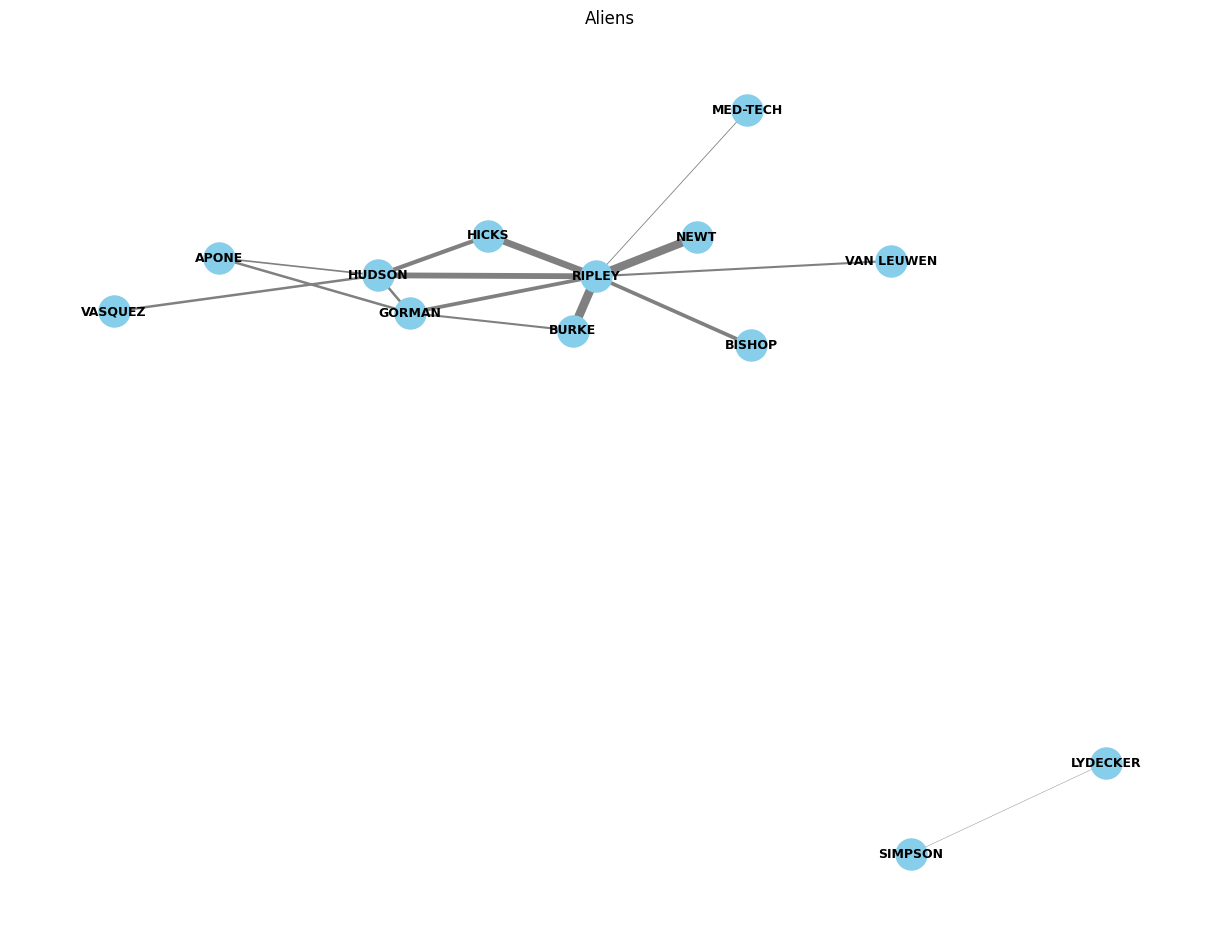

In [ ]:
pos = nx.spring_layout(G3, k=0.5, seed=1)    # seed makes the layout repeatable
edge_widths = [G3.edges[e]['weight'] * 0.3 for e in G3.edges()]

plt.figure(figsize=(12, 9))
nx.draw(G3, pos,
        with_labels=True,
        node_size=500,
        node_color="skyblue",
        width=edge_widths,
        edge_color="gray",
        font_size=9,
        font_weight="bold")
plt.title(movie_name.title())
plt.show()

### Making it readable

Some parameters worth experimenting with:

| Parameter | What it changes |
|---|---|
| `figsize=(w, h)` | More canvas means less overlap |
| `k` in `spring_layout` | Ideal distance between nodes; larger spreads the graph out |
| `seed` | Fixes the random starting layout so reruns look the same |
| `nx.kamada_kawai_layout(G3)` | A different layout algorithm; often tidier for small graphs |
| `font_size`, `node_size`, `alpha` | Label and node legibility |
| Dropping weak edges | Removes clutter from pairs who spoke only once |

For example, keeping only pairs with at least 2 conversations, with a different layout:

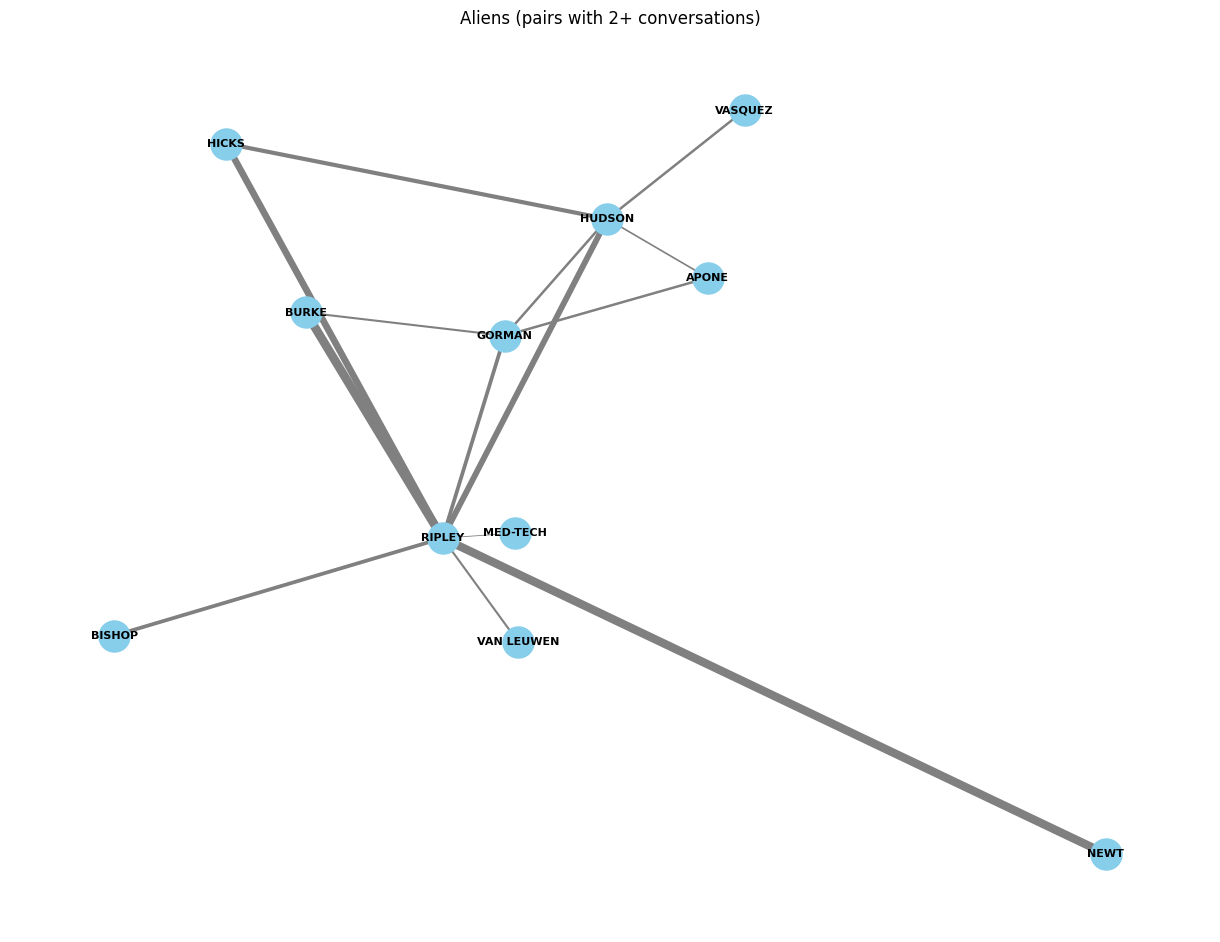

In [ ]:
strong = nx.Graph([(a, b, d) for a, b, d in G3.edges(data=True) if d['weight'] >= 2])

pos = nx.kamada_kawai_layout(strong)
plt.figure(figsize=(12, 9))
nx.draw(strong, pos, with_labels=True, node_size=500, node_color="skyblue",
        width=[strong.edges[e]['weight'] * 0.3 for e in strong.edges()],
        edge_color="gray", font_size=8, font_weight="bold")
plt.title(f"{movie_name.title()} (pairs with 2+ conversations)")
plt.show()

## Your turn

1. Copy this notebook (**File → Save a copy in Drive**) and change `movie_name` to a different movie
2. Graph the characters based on their conversations
3. Experiment with the visualization parameters until the graph is readable
4. Size each node by the **number of conversations that character appears in**: build a list `node_sizes` and pass `node_size=node_sizes` to `nx.draw()`
5. Post your graph to Discord with the name of the movie

Hints for step 4:
- Count conversations per character the same way we counted pairs: loop over `my_conversations` and add one for each character in it
- `node_sizes` must follow the order of `G3.nodes()`, one size per node
- Raw counts may be too small or too large to see; multiply by a constant until the differences are visible

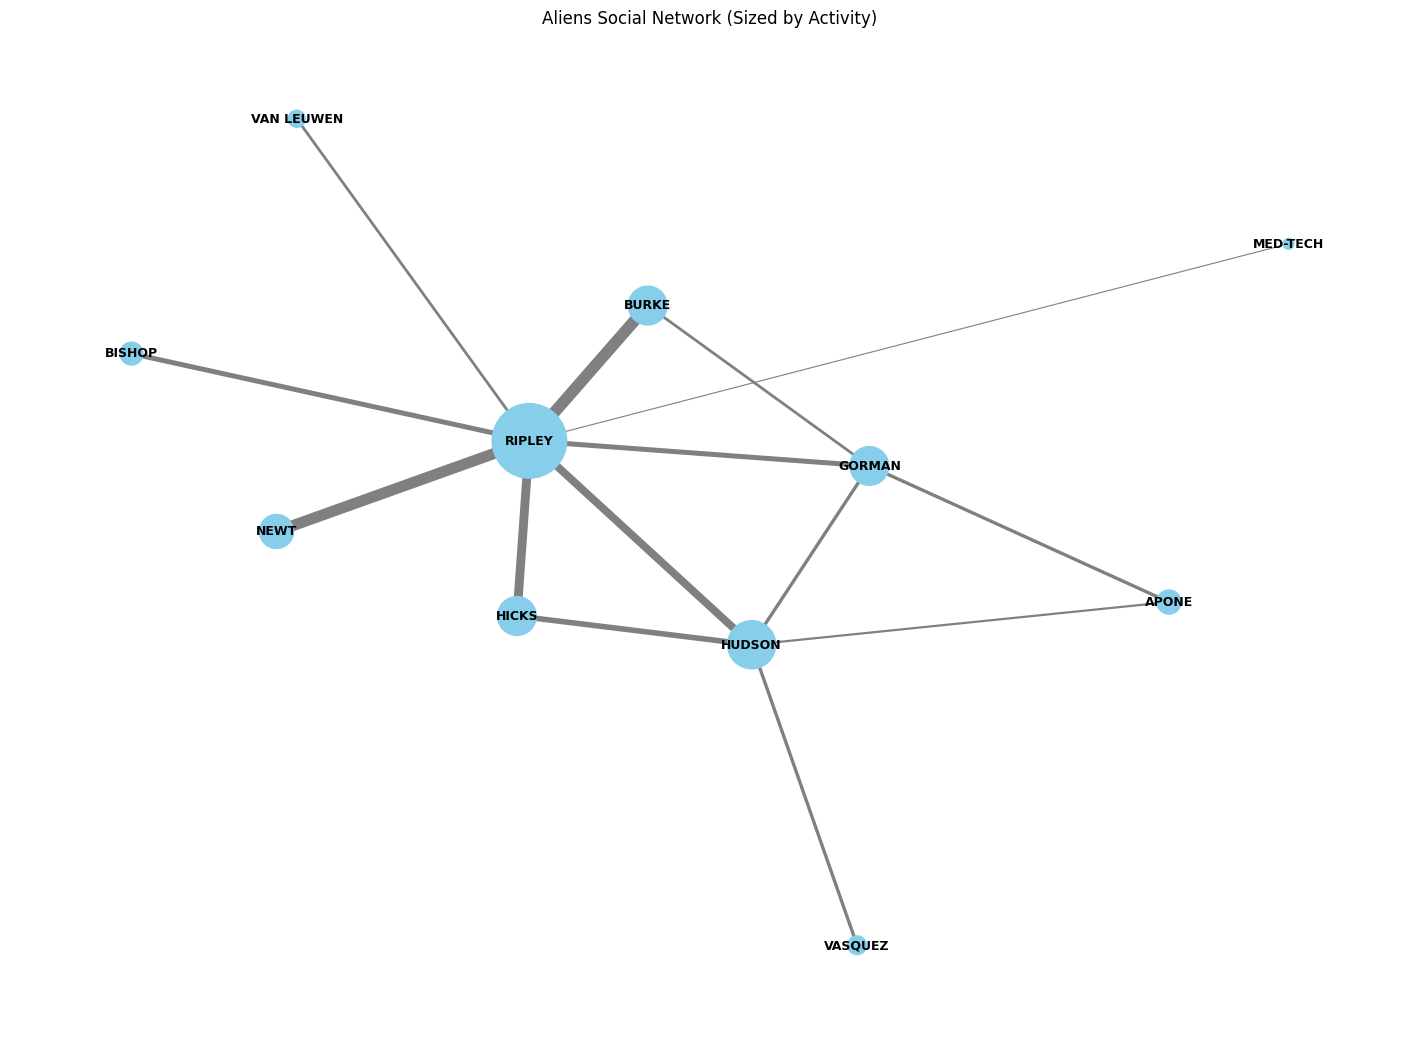

In [ ]:
# Counts how many conversations each character appears in.
character_counts = Counter()

for conv in my_conversations:
    # Gets unique
    names = sorted({character(s) for s in conv.iter_speakers()})
    for name in names:
        character_counts[name] += 1
# TODO: count the conversations each character appears in

node_sizes = [character_counts[node] * 30 for node in strong.nodes()]   # TODO: one size per node, in the order of G3.nodes()

pos = nx.spring_layout(strong, k=0.8, seed=1)
edge_widths = [strong.edges[e]['weight'] * 0.4 for e in strong.edges()]

plt.figure(figsize=(14, 10))
nx.draw(strong, pos,
        with_labels=True,
        node_size=node_sizes,
        node_color="skyblue",
        width=edge_widths,
        edge_color="gray",
        font_size=9,
        font_weight="bold")

plt.title(f"{movie_name.title()} Social Network (Sized by Activity)")

# TODO: draw G3 with node_size=node_sizes
plt.savefig("my_movie_graph.png", dpi=200, bbox_inches="tight")
plt.show()